# 04 - LSTM

Sequence model: instead of looking at *today's* features, feed the model
a **rolling window** of the last N days and let it learn temporal patterns.

This is the natural fit for time series - but it's also the most
**overfitting-prone** model in this project.

This notebook:

1. Checks TensorFlow availability (skip gracefully if missing)
2. Builds sliding windows from features
3. Trains a small LSTM
4. Compares against baseline / linear / trees
5. Plots training loss and predictions
6. Saves `reports/predictions/lstm.json`

**Warning**: LSTM training can take several minutes. Use a GPU if
you have one, otherwise reduce `EPOCHS` at the top of the training cell.


## Setup

In [13]:
# --- setup --------------------------------------------------------
import sys, json
sys.path.insert(0, r"D:\Projects\done\eth_bot\eth_bot_v2")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from analysis.loader import load_ohlcv
from analysis.indicators import add_all

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (12, 4)

SEED = 42
np.random.seed(SEED)

PRED_DIR = Path(r"D:\Projects\done\eth_bot\eth_bot_v2") / "reports" / "predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)

def load_json(name):
    p = PRED_DIR / name
    return json.loads(p.read_text()) if p.exists() else None

baseline = load_json("baseline.json")
linear   = load_json("linear.json")
trees    = load_json("trees.json")

print("baseline:", "loaded" if baseline else "missing")
print("linear  :", "loaded" if linear  else "missing")
print("trees   :", "loaded" if trees   else "missing")

try:
    import tensorflow as tf
    from tensorflow.keras import layers, models, callbacks
    HAS_TF = True
    print(f"tensorflow: {tf.__version__}")
    print(f"gpu       : {len(tf.config.list_physical_devices('GPU')) > 0}")
except ImportError:
    HAS_TF = False
    print("tensorflow NOT installed -- run: pip install tensorflow")
    print("cells below that need TF will be skipped")

baseline: loaded
linear  : missing
trees   : missing
tensorflow: 2.15.0
gpu       : False


## 1. Features

Same 9 features as notebooks 02 and 03. Windows will be built from
these columns.

In [14]:
def make_features(horizon: int = 1) -> pd.DataFrame:
    df = load_ohlcv()
    df = add_all(df).copy()

    df["ret_1"]  = df["close"].pct_change(1)
    df["ret_5"]  = df["close"].pct_change(5)
    df["ret_20"] = df["close"].pct_change(20)
    df["vol_20"] = df["ret_1"].rolling(20).std()

    df["target"] = df["close"].pct_change(horizon).shift(-horizon)
    return df.dropna()


FEATURES = [
    "ret_1", "ret_5", "ret_20", "vol_20",
    "rsi_14", "macd_hist", "atr_14",
    "sma_50", "sma_200",
]

df = make_features()
df = df[FEATURES + ["target"]].dropna()
print(f"rows: {len(df)}   features: {len(FEATURES)}")
df.tail(3)

rows: 1989   features: 9


,ret_1,ret_5,ret_20,vol_20,rsi_14,macd_hist,atr_14,sma_50,sma_200,target
date,,,,,,,,,,
2026-09-29,-0.003991,-0.003746,0.085024,0.024724,78.000000,-5.403658,94.379286,2420.3128,2107.85605,0.002999
2026-09-30,0.002999,-0.002081,0.101605,0.024423,77.459849,-7.424594,95.812143,2436.3812,2110.80530,0.007599
2026-10-01,0.007599,0.003742,0.075500,0.023603,77.054623,-7.781260,94.290000,2452.9134,2113.44590,-0.013978


## 2. Normalise features

Neural nets need standardised inputs. Fit on **train only** to avoid
leakage - never on the full dataset.

- `mean` and `std` computed from the first 85% of the data
- Applied to both train and test

In [15]:
WINDOW = 30                # days of history per sample
HORIZON = 1                # predict next day

raw_X = df[FEATURES].values
raw_y = df["target"].values

split_idx = int(len(df) * 0.85)
mu = raw_X[:split_idx].mean(axis=0)
sd = raw_X[:split_idx].std(axis=0) + 1e-9

X_norm = (raw_X - mu) / sd

print("mu:", mu.round(4))
print("sd:", sd.round(4))

mu: [ 1.0000000e-03  4.7000000e-03  1.9500000e-02  3.7000000e-02
  5.1427000e+01 -6.1420000e-01  1.4998670e+02  2.5684167e+03
  2.4539051e+03]
sd: [4.000000e-02 8.720000e-02 1.837000e-01 1.560000e-02 1.747630e+01
 3.493520e+01 8.285430e+01 8.588411e+02 6.798050e+02]


## 3. Build sliding windows

For each index `i >= WINDOW`, create:

- input: rows `[i-WINDOW : i]` - 30 days of features
- target: return at row `i` (the day after the window ends)

Result: `X.shape = (n_samples, WINDOW, n_features)`

In [16]:
def build_windows(X, y, window):
    Xs, ys = [], []
    for i in range(window, len(X)):
        Xs.append(X[i - window:i])
        ys.append(y[i])
    return np.array(Xs), np.array(ys)


X_win, y_win = build_windows(X_norm, raw_y, WINDOW)
print(f"X_win: {X_win.shape}   y_win: {y_win.shape}")

n_train = int(len(X_win) * 0.85)
X_train, y_train = X_win[:n_train], y_win[:n_train]
X_test,  y_test  = X_win[n_train:], y_win[n_train:]

print(f"train: {X_train.shape}   test: {X_test.shape}")

X_win: (1959, 30, 9)   y_win: (1959,)
train: (1665, 30, 9)   test: (294, 30, 9)


## 4. Build the LSTM

Small and simple on purpose:

- 2 stacked LSTM layers (64, then 32 units)
- dropout between them
- a small dense head that outputs a single number (next-day return)

**Bigger is worse here.** More layers means memorising training noise,
which does not generalise to test.

In [17]:
if not HAS_TF:
    print("skipping - tensorflow not installed")
else:
    tf.random.set_seed(SEED)

    model = models.Sequential([
        layers.Input(shape=(WINDOW, len(FEATURES))),
        layers.LSTM(64, return_sequences=True),
        layers.Dropout(0.3),
        layers.LSTM(32),
        layers.Dropout(0.2),
        layers.Dense(16, activation="relu"),
        layers.Dense(1),
    ])

    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_2 (LSTM)               (None, 30, 64)            18944     
                                                                 
 dropout_2 (Dropout)         (None, 30, 64)            0         
                                                                 
 lstm_3 (LSTM)               (None, 32)                12416     
                                                                 
 dropout_3 (Dropout)         (None, 32)                0         
                                                                 
 dense_2 (Dense)             (None, 16)                528       
                                                                 
 dense_3 (Dense)             (None, 1)                 17        
                                                                 
Total params: 31905 (124.63 KB)
Trainable params: 3190

## 5. Train

- Early stopping: stop if val loss does not improve for 10 epochs
- Model checkpoint: keep the best epoch's weights
- `EPOCHS = 40` - if it takes too long, drop to 15

In [18]:
if not HAS_TF:
    print("skipping - tensorflow not installed")
else:
    EPOCHS = 40
    BATCH  = 32

    cb = [
        callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                restore_best_weights=True),
        callbacks.ModelCheckpoint(str(PRED_DIR / "lstm.keras"),
                                  monitor="val_loss", save_best_only=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                    patience=5, min_lr=1e-5),
    ]

    history = model.fit(
        X_train, y_train,
        validation_split=0.1,
        epochs=EPOCHS,
        batch_size=BATCH,
        callbacks=cb,
        verbose=1,
    )

Epoch 1/40
47/47 [==============================] - 8s 54ms/step - loss: 0.0047 - val_loss: 0.0015 - lr: 0.0010
Epoch 2/40
47/47 [==============================] - 1s 31ms/step - loss: 0.0019 - val_loss: 0.0014 - lr: 0.0010
Epoch 3/40
47/47 [==============================] - 1s 26ms/step - loss: 0.0017 - val_loss: 0.0015 - lr: 0.0010
Epoch 4/40
47/47 [==============================] - 1s 29ms/step - loss: 0.0016 - val_loss: 0.0014 - lr: 0.0010
Epoch 5/40
47/47 [==============================] - 2s 34ms/step - loss: 0.0016 - val_loss: 0.0014 - lr: 0.0010
Epoch 6/40
47/47 [==============================] - 2s 36ms/step - loss: 0.0015 - val_loss: 0.0014 - lr: 0.0010
Epoch 7/40
47/47 [==============================] - 1s 29ms/step - loss: 0.0015 - val_loss: 0.0014 - lr: 5.0000e-04
Epoch 8/40
47/47 [==============================] - 1s 25ms/step - loss: 0.0015 - val_loss: 0.0014 - lr: 5.0000e-04
Epoch 9/40
47/47 [==============================] - 1s 24ms/step - loss: 0.0015 - val_loss: 0.00

## 6. Training curve

Loss should drop on train, and stop dropping on validation when it starts overfitting.

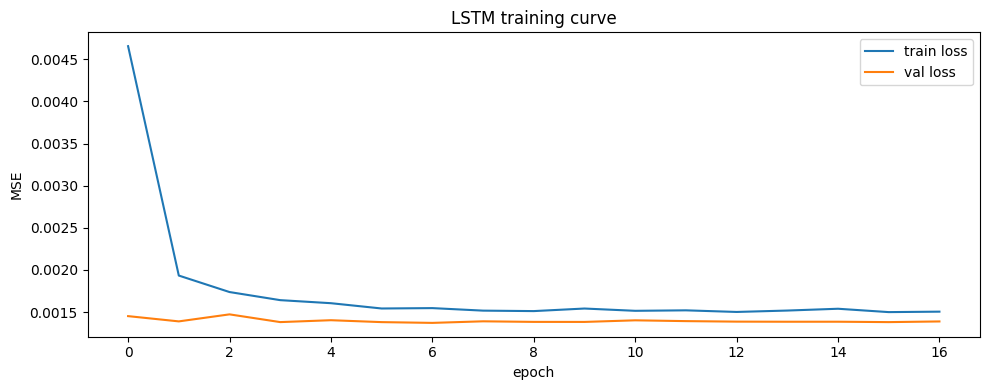

best epoch: 6   val_loss: 0.001372


In [19]:
if not HAS_TF:
    print("skipping - tensorflow not installed")
else:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(history.history["loss"],     label="train loss")
    ax.plot(history.history["val_loss"], label="val loss")
    ax.set_xlabel("epoch")
    ax.set_ylabel("MSE")
    ax.set_title("LSTM training curve")
    ax.legend()
    plt.tight_layout()
    plt.show()

    best_epoch = int(np.argmin(history.history["val_loss"]))
    print(f"best epoch: {best_epoch}   val_loss: {history.history['val_loss'][best_epoch]:.6f}")

## 7. Evaluate on the test window

In [20]:
if not HAS_TF:
    rmse = mae = dir_acc = float("nan")
else:
    pred = model.predict(X_test, verbose=0).flatten()

    rmse = float(np.sqrt(((pred - y_test) ** 2).mean()))
    mae  = float(np.abs(pred - y_test).mean())
    dir_acc = float(((pred > 0) == (y_test > 0)).mean())

    print("LSTM")
    print(f"  RMSE         : {rmse:.6f}")
    print(f"  MAE          : {mae:.6f}")
    print(f"  dir accuracy : {dir_acc:.2%}")

LSTM
  RMSE         : 0.031971
  MAE          : 0.021341
  dir accuracy : 55.78%


## 8. Compare to previous models

Loads baseline / linear / trees from disk and builds a combined table.

In [21]:
rows = []
if baseline:
    rows.append({"model": "baseline",
                 "rmse": baseline["return"]["rmse"],
                 "mae":  baseline["return"]["mae"],
                 "dir_accuracy": baseline["return"]["dir_accuracy"]})
if linear:
    rows.append({"model": "linear",
                 "rmse": linear["rmse"],
                 "mae":  linear["mae"],
                 "dir_accuracy": linear["dir_accuracy"]})
if trees:
    rows.append({"model": "best_tree",
                 "rmse": trees["best_rmse"],
                 "mae":  float("nan"),
                 "dir_accuracy": trees["best_dir"]})
rows.append({"model": "lstm", "rmse": rmse, "mae": mae, "dir_accuracy": dir_acc})

comp = pd.DataFrame(rows)
comp

,model,rmse,mae,dir_accuracy
0,baseline,0.032920,0.021931,0.520000
1,lstm,0.031971,0.021341,0.557823


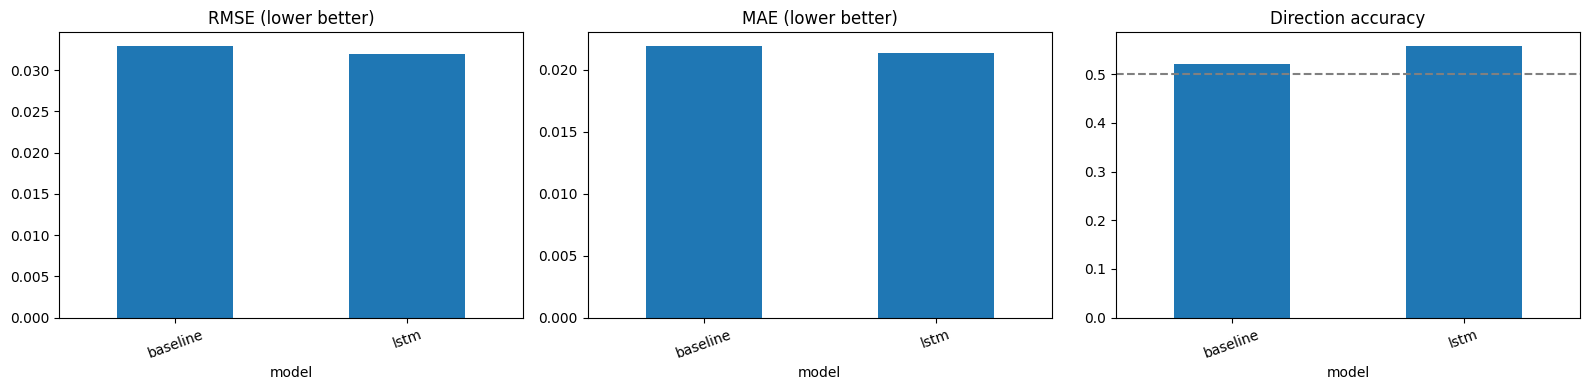

In [22]:
if len(comp) > 1:
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    comp.plot.bar(x="model", y="rmse",         ax=ax[0], title="RMSE (lower better)", legend=False)
    comp.plot.bar(x="model", y="mae",          ax=ax[1], title="MAE (lower better)",  legend=False)
    comp.plot.bar(x="model", y="dir_accuracy", ax=ax[2], title="Direction accuracy",  legend=False)
    ax[2].axhline(0.5, ls="--", color="gray")
    for a in ax:
        a.tick_params(axis="x", rotation=20)
    plt.tight_layout()
    plt.show()

## 9. Predictions vs actual

Same visual as previous notebooks - for direct comparison.

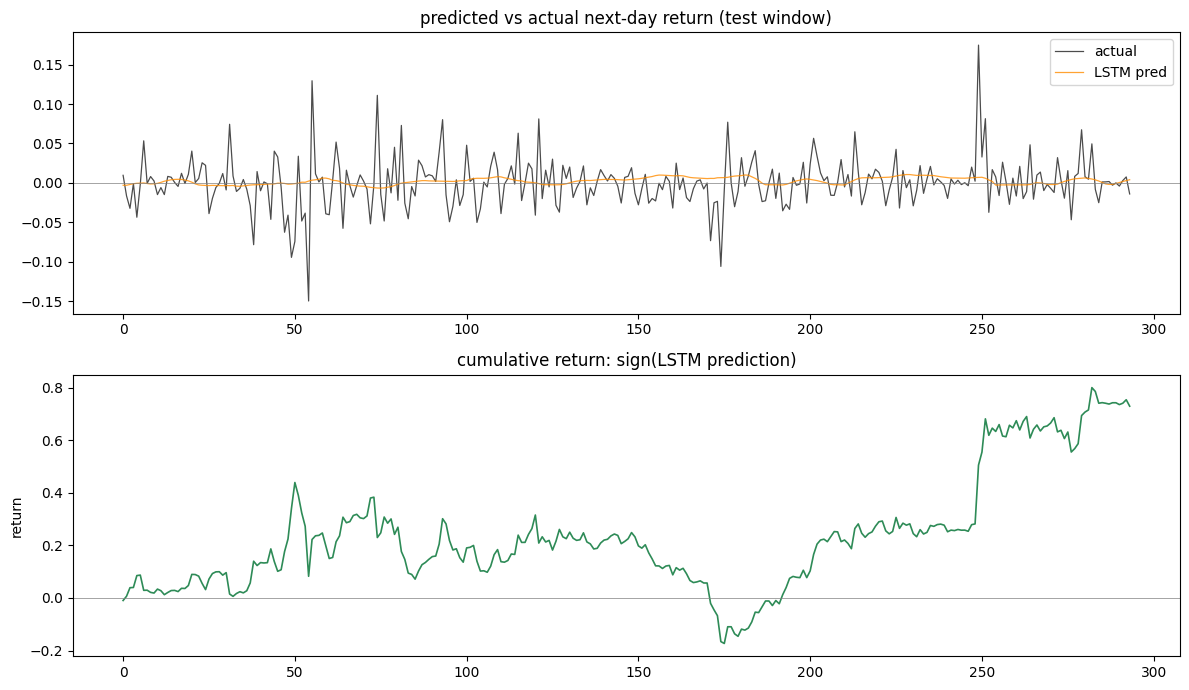

strategy total return: +72.99%
strategy sharpe      : 1.42


In [23]:
if HAS_TF:
    fig, ax = plt.subplots(2, 1, figsize=(12, 7))

    ax[0].plot(y_test, label="actual",   color="black",      lw=0.9, alpha=0.7)
    ax[0].plot(pred,   label="LSTM pred", color="darkorange", lw=0.9, alpha=0.8)
    ax[0].axhline(0, color="gray", lw=0.5)
    ax[0].set_title("predicted vs actual next-day return (test window)")
    ax[0].legend()

    position = np.sign(pred)
    pnl = position * y_test
    cum_pnl = (1 + pnl).cumprod() - 1

    ax[1].plot(cum_pnl, color="seagreen", lw=1.2)
    ax[1].axhline(0, color="gray", lw=0.5)
    ax[1].set_title("cumulative return: sign(LSTM prediction)")
    ax[1].set_ylabel("return")

    plt.tight_layout()
    plt.show()

    print(f"strategy total return: {cum_pnl[-1]:+.2%}")
    print(f"strategy sharpe      : {pnl.mean() / pnl.std() * np.sqrt(365):.2f}")
else:
    print("skipping - tensorflow not installed")

## 10. Save results

Writes `reports/predictions/lstm.json`.

In [24]:
out = {
    "model": "lstm",
    "window": WINDOW,
    "features": FEATURES,
    "epochs_run": int(len(history.history["loss"])) if HAS_TF else 0,
    "best_epoch": int(np.argmin(history.history["val_loss"])) if HAS_TF else None,
    "test_days": int(len(y_test)),
    "rmse": rmse,
    "mae":  mae,
    "dir_accuracy": dir_acc,
}

path = PRED_DIR / "lstm.json"
path.write_text(json.dumps(out, indent=2), encoding="utf-8")
print("wrote", path)

wrote D:\Projects\done\eth_bot\eth_bot_v2\reports\predictions\lstm.json


## Next steps

**Interpreting the LSTM result**

| Situation | What it means |
|---|---|
| LSTM is close to linear/trees | sequence adds nothing - the 30-day window is overkill |
| LSTM clearly worse | overfit - reduce units, increase dropout, reduce epochs |
| LSTM clearly better | rare - investigate, but be suspicious of leakage |

**For daily crypto returns**, LSTM usually ties or underperforms
the simple models. It is worth trying, not worth betting on.

- **05_walkforward.ipynb** - honest evaluation: does any model work across many windows?
- **06_feature_importance.ipynb** - SHAP for tree models
- **07_model_comparison.ipynb** - combined leaderboard

**Real talk**: the next 5% of improvement will come from adding
`funding_rate`, `open_interest`, and `fear_greed` as features -
not from a bigger LSTM. Try that before adding layers.
